# seq2seq模型——机器翻译

### 案例简介

seq2seq是神经机器翻译的主流框架，如今的商用机器翻译系统大多都基于其构建，在本案例中，我们将使用由NIST提供的中英文本数据训练一个简单的中英翻译系统，在实践中学习seq2seq的具体细节，以及了解机器翻译的基本技术。

### seq2seq模型

从根本上讲，机器翻译需要将输入序列（源语言中的单词）映射到输出序列（目标语言中的单词）。正如我们在课堂上讨论的那样，递归神经网络（RNN）可有效处理此类顺序数据。机器翻译中的一个重要难题是输入和输出序列之间没有一对一的对应关系。即，序列通常具有不同的长度，并且单词对应可以是不平凡的（例如，彼此直接翻译的单词可能不会以相同的顺序出现）。

为了解决这个问题，我们将使用一种更灵活的架构，称为seq2seq模型。该模型由编码器和解码器两部分组成，它们都是RNN。编码器将源语言中的单词序列作为输入，并输出RNN层的最终隐藏状态。解码器与之类似，除了它还具有一个附加的全连接层（带有softmax激活），用于定义翻译中下一个单词的概率分布。以此方式，解码器本质上用作目标语言的神经语言模型。关键区别在于，解码器将编码器的输出用作其初始隐藏状态，而不是零向量。

### 数据和代码

本案例使用了一个小规模的中英平行语料数据，并提供了一个简单的seq2seq模型实现，包括数据的预处理、模型的训练、以及简单的评测。

### 评分要求

分数由两部分组成，各占50%。第一部分得分为对于简单seq2seq模型的改进，并撰写实验报告，改进方式多样，下一小节会给出一些可能的改进方向。第二分部得分为测试数据的评测结果，我们将给出一个中文测试数据集（`test.txt`），其中每一行为一句中文文本，需要同学提交模型做出的对应翻译结果，助教将对于大家的提交结果统一机器评测，并给出分数。

### 改进方向

初级改进：
- 将RNN模型替换成GRU或者LSTM
- 使用双向的encoder获得更好的源语言表示
- 对于现有超参数进行调优，这里建议划分出一个开发集，在开发集上进行grid search，并且在报告中汇报开发集结果
- 引入更多的训练语料（如果尝试复杂模型，更多的训练数据将非常关键）

进阶改进：
- 使用注意力机制（注意力机制是一个很重要的NMT技术，建议大家优先进行这方面的尝试，具体有许多种变体，可以参考这个[综述](https://nlp.stanford.edu/pubs/emnlp15_attn.pdf)）
- 在Encoder部分，使用了字级别的中文输入，可以考虑加入分词的结果，并且将Encoder的词向量替换为预训练过的词向量，获得更好的性能

复杂改进：
- 使用beam search的技术来帮助更好的解码，对于beam-width进行调优
- 将RNN替换为Transformer模型，以及最新的改进变体

## 环境依赖

In [1]:
import unicodedata
import string
import re
import random
import time
import math

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

如果使用GPU，则将下面的变量设为`True`。

In [2]:
USE_CUDA = True

## 读取数据

我们将读取目录下的`cn-eng.txt`文件，其中每一行是一个平行句对，例子如下：

```
我很冷。    I am cold.
```

### 对于单词进行编号

这里引入了两个特殊符号，“SOS”即“Start of sentence”和“EOS”即“End of sentence”。他们会加到输入文本的两端，以控制解码过程。

In [3]:
'''
考虑了验证集/测试集未登录词(OOV)的处理，在此表中加入了未知词索引，并设置低频词过滤
对原代码做了相应改动
'''
SOS_token = 1  # 修改原索引 0（batch计算中0被用于padding）
EOS_token = 2  # 修改原索引 1（1被用于SOS索引）
UNK_token = 3  # 添加未知索引

class Lang:
    def __init__(self, name, min_count=1):
        self.name = name
        self.min_count = min_count
        # 特殊词索引（PAD=0 保留，但不一定使用）
        self.word2index = {"<SOS>": SOS_token, "<EOS>": EOS_token, "<UNK>": UNK_token}
        self.word2count = {}
        self.index2word = {SOS_token: "<SOS>", EOS_token: "<EOS>", UNK_token: "<UNK>"}
        self.n_words = 4   # 下一个新词索引从4开始

    def add_sentence(self, sentence):
        """先统计所有词的频率（不构建词表）"""
        if self.name == 'cn':
            words = list(sentence)
        else:
            words = sentence.split(' ')
        for w in words:
            self.word2count[w] = self.word2count.get(w, 0) + 1

    def finalize(self):
        """根据 min_count 过滤低频词，构建最终词表"""
        for w, cnt in self.word2count.items():
            if cnt >= self.min_count:
                if w not in self.word2index:
                    self.word2index[w] = self.n_words
                    self.index2word[self.n_words] = w
                    self.n_words += 1

    def indexes_from_sentence(self, sentence):
        """将句子转为索引，低频词/未知词替换为 UNK 索引"""
        if self.name == 'cn':
            words = list(sentence)
        else:
            words = sentence.split(' ')
        indexes = []
        for w in words:
            idx = self.word2index.get(w, self.word2index["<UNK>"])
            indexes.append(idx)
        return indexes

### 文本预处理

丢弃除了中文、字母和常用标点之外的符号。

In [4]:
# Turn a Unicode string to plain ASCII, thanks to http://stackoverflow.com/a/518232/2809427
def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalize_string(s):
    s = unicode_to_ascii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z\u4e00-\u9fa5.!?，。？]+", r" ", s)
    return s

读取平行语料，并进行清理。

In [5]:
def read_langs(lang1, lang2, reverse=False):
    print("Reading lines...")

    # Read the file and split into lines
    lines = open('%s-%s.txt' % (lang1, lang2), encoding='utf-8').read().strip().split('\n')
    
    # Split every line into pairs and normalize
    pairs = [[normalize_string(s) for s in l.split('\t')] for l in lines]
    
    # Reverse pairs, make Lang instances
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)
        
    return input_lang, output_lang, pairs

### 过滤句子

样例为了加快训练，只保留了不长于10个单词的句对，真正实验中将更多数据考虑进来可能获得更好的效果。

In [6]:
MAX_LENGTH = 10

def filter_pair(p):
    return len(p[1].split(' ')) < MAX_LENGTH

def filter_pairs(pairs):
    return [pair for pair in pairs if filter_pair(pair)]

### 划分验证集

In [7]:
import numpy as np

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # 如果使用 GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 设置种子
set_seed(42)

In [8]:
def split_train_val(pairs, val_ratio=0.1):
    """
    将句子对拆分为训练集和验证集
    
    Args:
        pairs: 句子对列表，格式为[[src_sent, tgt_sent], ...]
        val_ratio: 验证集比例，默认0.2
        random_seed: 随机种子，默认42
    
    Returns:
        train_pairs: 训练集
        val_pairs: 验证集
    """
    random.shuffle(pairs)   # 现在 shuffle 结果固定（因已固定种子）

    total = len(pairs)
    train_split = total - int(total * val_ratio)   # 90% 训练

    train_pairs = pairs[:train_split]
    val_pairs = pairs[train_split:]

    print(f"总数据集大小: {len(pairs)}")
    print(f"训练集大小: {len(train_pairs)} ({len(train_pairs)/total:.1%})")
    print(f"验证集大小: {len(val_pairs)} ({len(val_pairs)/total:.1%})")
    
    return train_pairs, val_pairs

### 数据准备

处理数据的全过程：

- 读取数据，每一行分别处理，将其转换成句对
- 对于文本进行处理，过滤无用符号
- **数据集划分**
- 根据已有文本对于单词进行编号，构建符号到编号的映射


In [9]:
'''
词表类Lang中引入了<UNK>，词表构建方法也做相应修改
'''
def prepare_data(lang1_name, lang2_name, reverse=False, min_count=1):
    input_lang, output_lang, pairs = read_langs(lang1_name, lang2_name, reverse)
    print("Read %s sentence pairs" % len(pairs))

    pairs = filter_pairs(pairs)
    print("Trimmed to %s sentence pairs" % len(pairs))

    train_pairs, val_pairs = split_train_val(pairs)

    # 第一遍：统计词频（不构建词表）
    print("Counting words on train data...")
    for src, tgt in train_pairs:
        input_lang.add_sentence(src)
        output_lang.add_sentence(tgt)

    # 第二遍：根据 min_count 构建最终词表（低频词归为 UNK）
    print("Building vocabularies on train data(min_count=%d)..." % min_count)
    input_lang.finalize()
    output_lang.finalize()

    print("Input vocabulary size: %d" % input_lang.n_words)
    print("Output vocabulary size: %d" % output_lang.n_words)
    return input_lang, output_lang, train_pairs, val_pairs

input_lang, output_lang, train_pairs, val_pairs = prepare_data('cn', 'eng', reverse=False, min_count=2)
print(random.choice(train_pairs))

Reading lines...
Read 90000 sentence pairs
Trimmed to 68898 sentence pairs
总数据集大小: 68898
训练集大小: 62009 (90.0%)
验证集大小: 6889 (10.0%)
Counting words on train data...
Building vocabularies on train data(min_count=2)...
Input vocabulary size: 3883
Output vocabulary size: 8855
['她買了兩雙襪子。', 'she bought two pairs of socks .']


## 将文本数据转换为张量

为了训练，我们需要将句子变成神经网络可以理解的东西（数字）。每个句子将被分解成单词，然后变成张量，其中每个单词都被索引替换（来自之前的Lang索引）。在创建这些张量时，我们还将附加EOS令牌以表示该句子已结束。

![](https://i.imgur.com/LzocpGH.png)

In [10]:
'''
Lang类中加入了indexes_from_sentence方法
'''
# Return a list of indexes, one for each word in the sentence
# def indexes_from_sentence(lang, sentence):
#     if lang.name == 'cn':
#         return [lang.word2index[word] for word in sentence]
#     else:
#         return [lang.word2index[word] for word in sentence.split(' ')]

def variable_from_sentence(lang, sentence, add_batch_dim=False):
    """
    将句子转为模型输入张量
    Args:
        lang: Lang 实例
        sentence: 输入句子字符串
        add_batch_dim: 是否添加 batch 维度（即返回形状 (1, seq_len)）
    Returns:
        torch.LongTensor: 形状 (seq_len,) 或 (1, seq_len)
    """
    indexes = lang.indexes_from_sentence(sentence) + [EOS_token]
    tensor = torch.LongTensor(indexes)          # (seq_len,)
    if add_batch_dim:
        tensor = tensor.unsqueeze(0)            # (1, seq_len)
    if USE_CUDA: tensor = tensor.cuda()   
    return tensor

def variables_from_pair(pair):
    input_variable = variable_from_sentence(input_lang, pair[0])
    target_variable = variable_from_sentence(output_lang, pair[1])
    return (input_variable, target_variable)

# <font color=red>组件模型</font>

## <font color=red>编码器(GRU)</font>

**编码器和解码器都使用GRU代替RNN**

In [11]:
class EncoderGRU(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers=1):
        super(EncoderGRU, self).__init__()
        
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        
        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers)   # 仅改这里
        
    def forward(self, word_inputs, hidden):
        # word_inputs: (seq_len,)  一维张量
        seq_len = len(word_inputs)
        embedded = self.embedding(word_inputs).view(seq_len, 1, -1)
        output, hidden = self.gru(embedded, hidden)
        return output, hidden

    def init_hidden(self):
        hidden = torch.zeros(self.n_layers, 1, self.hidden_size)
        if USE_CUDA:
            hidden = hidden.cuda()
        return hidden

## <font color=red>解码器(GRU)</font>

In [12]:
class DecoderGRU(nn.Module):
    def __init__(self, hidden_size, output_size, n_layers=1, dropout_p=0.1):
        super(DecoderGRU, self).__init__()
        
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers
        self.dropout_p = dropout_p
        
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers, dropout=dropout_p)
        self.out = nn.Linear(hidden_size, output_size)
    
    def forward(self, word_input, last_hidden):
        # word_input: (1,1)  或 (1,) 但建议保持 (1,1)
        word_embedded = self.embedding(word_input).view(1, 1, -1)   # (1,1,hidden)
        rnn_output, hidden = self.gru(word_embedded, last_hidden)
        rnn_output = rnn_output.squeeze(0)          # (1, hidden)
        output = F.log_softmax(self.out(rnn_output), dim=-1)   # 注意加上 dim=-1
        return output, hidden

# 训练

## 一次训练迭代

为了训练，我们首先通过编码器逐字运行输入语句，并跟踪每个输出和最新的隐藏状态。接下来，为解码器提供解码器的最后一个隐藏状态作为其第一隐藏状态，并向其提供`<SOS>`作为其第一输入。从那里开始，我们迭代地预测来自解码器的下一个单词。
    
### Teacher Forcing 和 Scheduled Sampling

"Teacher Forcing"指的是每次都基于完全准确的上文进行解码，这样训练模型收敛很快，但是会造成实际场景和训练场景有较大差别，因为实际场景上文也都是模型预测的，可能不准确，具体细节可参考[论文](http://minds.jacobs-university.de/sites/default/files/uploads/papers/ESNTutorialRev.pdf)。

观察Teacher Forcing的网络的输出，我们可以看到该网络语法连贯，但是偏离正确的翻译。可以将其为学会了如何听老师的指示，而未学习如何独自冒险。

解决强迫教师问题的方法称为“计划抽样”（[Scheduled Sampling](https://arxiv.org/abs/1506.03099)），它在训练时仅在使用目标值和预测值之间进行切换。我们将在训练时随机选择,有时我们将使用真实目标作为输入（忽略解码器的输出），有时我们将使用解码器的输出。

In [13]:
teacher_forcing_ratio = 0.5
clip = 5.0

def train(input_variable, target_variable, encoder, decoder,
          encoder_optimizer, decoder_optimizer, criterion, max_length=MAX_LENGTH):

    # Zero gradients of both optimizers
    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()
    loss = 0 # Added onto for each word

    # Get size of input and target sentences
    input_length = input_variable.size()[0]
    target_length = target_variable.size()[0]

    # Run words through encoder
    encoder_hidden = encoder.init_hidden()
    encoder_outputs, encoder_hidden = encoder(input_variable, encoder_hidden)
    
    # Prepare input and output variables
    decoder_input = torch.LongTensor([[SOS_token]])
    if USE_CUDA:
        decoder_input = decoder_input.cuda()
    decoder_hidden = encoder_hidden # Use last hidden state from encoder to start decoder

    # Choose whether to use teacher forcing
    use_teacher_forcing = random.random() < teacher_forcing_ratio
    decoded_steps = 0
    if use_teacher_forcing:
        
        # Teacher forcing: Use the ground-truth target as the next input
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
            # decoder_output: (1, output_size)
            # 目标形状：需要 (1,) 或标量；这里使用 view(1) 显式转为 (1,)
            loss += criterion(decoder_output, target_variable[di].view(1))
            # 下一步输入：真实目标词，形状需保持 (1,1)
            decoder_input = target_variable[di].view(1, 1) # Next target is next input
            decoded_steps += 1
    else:
        # Without teacher forcing: use network's own prediction as the next input
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
            loss += criterion(decoder_output, target_variable[di].view(1))
            
            # Get most likely word index (highest value) from output
            topv, topi = decoder_output.data.topk(1)
            ni = topi[0][0]
            
            decoder_input = torch.LongTensor([[ni]]) # Chosen word is next input
            if USE_CUDA: decoder_input = decoder_input.cuda()

            # Stop at end of sentence (not necessary when using known targets)
            if ni == EOS_token: break

    # Backpropagation
    loss.backward()
    torch.nn.utils.clip_grad_norm(encoder.parameters(), clip)
    torch.nn.utils.clip_grad_norm(decoder.parameters(), clip)
    encoder_optimizer.step()
    decoder_optimizer.step()
    
    # 使用实际解码步数求平均损失
    return loss.item() / decoded_steps if decoded_steps > 0 else 0

下面是用于辅助输出训练情况的函数

In [14]:
def as_minutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)

def time_since(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (as_minutes(s), as_minutes(rs))

## 进行训练

In [16]:
hidden_size = 500
n_layers = 2
dropout_p = 0.05

# Initialize models
encoder = EncoderGRU(input_lang.n_words, hidden_size, n_layers)
decoder = DecoderGRU(hidden_size, output_lang.n_words, n_layers, dropout_p=dropout_p)

# Move models to GPU
if USE_CUDA:
    encoder.cuda()
    decoder.cuda()

# Initialize optimizers and criterion
learning_rate = 0.0001
encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
criterion = nn.NLLLoss()

以下设置变量用于绘制图标和跟踪进度：

In [17]:
# Configuring training
n_epochs = 50000
plot_every = 200
print_every = 1000

# Keep track of time elapsed and running averages
start = time.time()
plot_losses = []
print_loss_total = 0 # Reset every print_every
plot_loss_total = 0 # Reset every plot_every

要进行实际训练，我们会多次调用训练函数，并在进行过程中打印中间信息。

In [18]:
# Begin!
for epoch in range(1, n_epochs + 1):
    
    # Get training data for this cycle
    training_pair = variables_from_pair(random.choice(train_pairs))
    input_variable = training_pair[0]
    target_variable = training_pair[1]

    # Run the train function
    loss = train(input_variable, target_variable, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion)

    # Keep track of loss
    print_loss_total += loss
    plot_loss_total += loss

    if epoch == 0: continue

    if epoch % print_every == 0:
        print_loss_avg = print_loss_total / print_every
        print_loss_total = 0
        print_summary = '%s (%d %d%%) %.4f' % (time_since(start, epoch / n_epochs), epoch, epoch / n_epochs * 100, print_loss_avg)
        print(print_summary)

    if epoch % plot_every == 0:
        plot_loss_avg = plot_loss_total / plot_every
        plot_losses.append(plot_loss_avg)
        plot_loss_total = 0

C:\Users\gaott\AppData\Local\Temp\ipykernel_13704\3717400284.py:58: UserWarning: torch.nn.utils.clip_grad_norm is now deprecated in favor of torch.nn.utils.clip_grad_norm_.
  torch.nn.utils.clip_grad_norm(encoder.parameters(), clip)
C:\Users\gaott\AppData\Local\Temp\ipykernel_13704\3717400284.py:59: UserWarning: torch.nn.utils.clip_grad_norm is now deprecated in favor of torch.nn.utils.clip_grad_norm_.
  torch.nn.utils.clip_grad_norm(decoder.parameters(), clip)


1m 17s (- 63m 35s) (1000 2%) 2.6627
2m 32s (- 60m 59s) (2000 4%) 2.2483
3m 49s (- 59m 49s) (3000 6%) 2.1228
5m 4s (- 58m 26s) (4000 8%) 2.1882
6m 19s (- 56m 58s) (5000 10%) 2.2094
7m 35s (- 55m 38s) (6000 12%) 2.2173
8m 51s (- 54m 26s) (7000 14%) 1.9508
10m 7s (- 53m 6s) (8000 16%) 1.9472
11m 25s (- 52m 4s) (9000 18%) 2.0015
12m 57s (- 51m 48s) (10000 20%) 2.0337
14m 49s (- 52m 32s) (11000 22%) 1.8424
16m 14s (- 51m 27s) (12000 24%) 1.7275
17m 30s (- 49m 50s) (13000 26%) 1.8546
18m 45s (- 48m 15s) (14000 28%) 1.8828
20m 0s (- 46m 41s) (15000 30%) 1.8287
21m 17s (- 45m 14s) (16000 32%) 1.7806
22m 40s (- 44m 1s) (17000 34%) 1.8274
24m 21s (- 43m 18s) (18000 36%) 1.7499
25m 59s (- 42m 24s) (19000 38%) 1.7287
27m 43s (- 41m 34s) (20000 40%) 1.5039
29m 24s (- 40m 36s) (21000 42%) 1.6365
30m 44s (- 39m 7s) (22000 44%) 1.5182
32m 1s (- 37m 35s) (23000 46%) 1.6992
33m 17s (- 36m 4s) (24000 48%) 1.6936
34m 33s (- 34m 33s) (25000 50%) 1.6368
35m 48s (- 33m 3s) (26000 52%) 1.6036
37m 3s (- 31m 34

## 绘制训练loss

<Figure size 640x480 with 0 Axes>

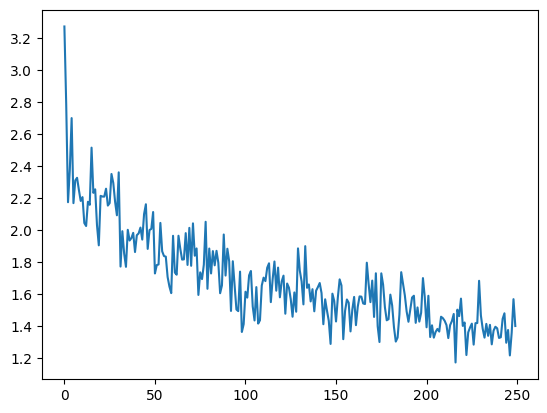

In [19]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
%matplotlib inline

def show_plot(points):
    plt.figure()
    fig, ax = plt.subplots()
    loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)

show_plot(plot_losses)

# 模型验证

In [20]:
def evaluate(sentence, max_length=MAX_LENGTH):
    input_variable = variable_from_sentence(input_lang, sentence)
    input_length = input_variable.size()[0]
    
    # Run through encoder
    encoder_hidden = encoder.init_hidden()
    encoder_outputs, encoder_hidden = encoder(input_variable, encoder_hidden)

    # Create starting vectors for decoder
    decoder_input = torch.LongTensor([[SOS_token]]) # SOS
    if USE_CUDA:
        decoder_input = decoder_input.cuda()

    decoder_hidden = encoder_hidden
    
    decoded_words = []
    decoder_attentions = torch.zeros(max_length, max_length)
    
    # Run through decoder
    for di in range(max_length):
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
        # Choose top word from output
        topv, topi = decoder_output.data.topk(1)
        ni = topi[0][0]
        if ni == EOS_token:
            decoded_words.append('<EOS>')
            break
        else:
            decoded_words.append(output_lang.index2word[ni.item()])
            
        # Next input is chosen word
        decoder_input = torch.LongTensor([[ni]])
        if USE_CUDA: decoder_input = decoder_input.cuda()

    output_sentence = ' '.join([w for w in decoded_words if w not in ('<EOS>', '<SOS>', '<PAD>')])
    
    return output_sentence

随机选取一个句子进行验证。

In [21]:
def evaluate_randomly(pairs):
    pair = random.choice(pairs)
    
    output_sentence = evaluate(pair[0])
    
    print('>', pair[0])
    print('=', pair[1])
    print('<', output_sentence)
    print('')

print("====== 随机训练集 ======")
evaluate_randomly(train_pairs)

print("\n====== 随机验证集 ======")
evaluate_randomly(val_pairs)

====== 随机训练集 ======
> 我打算買支筆送給他。
= i ll buy a pen for him .
< i ll call him to buy a . .


====== 随机验证集 ======
> 他們在下棋。
= they re playing chess .
< they re here .



**用验证集计算BLEU：**

In [22]:
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu
from nltk.translate.bleu_score import SmoothingFunction
import numpy as np

def calculate_bleu(references, hypotheses):
    """
    计算BLEU分数
    
    Args:
        references: 参考译文列表，每个元素是参考句子的分词列表
        hypotheses: 模型预测的译文列表，每个元素是预测句子的分词列表
    """
    # 使用平滑函数处理短句子
    smoothie = SmoothingFunction().method4
    
    # 计算句子级别的BLEU
    sentence_bleu_scores = []
    for ref, hyp in zip(references, hypotheses):
        # 注意：sentence_bleu的reference需要是列表的列表
        score = sentence_bleu([ref], hyp, 
                              weights=(0.25, 0.25, 0.25, 0.25),
                              smoothing_function=smoothie)
        sentence_bleu_scores.append(score)
    
    # 计算语料库级别的BLEU
    corpus_bleu_score = corpus_bleu([[ref] for ref in references], 
                                    hypotheses,
                                    smoothing_function=smoothie)
    
    return {
        'corpus_bleu': corpus_bleu_score,
        'mean_sentence_bleu': np.mean(sentence_bleu_scores),
        'sentence_bleus': sentence_bleu_scores
    }

In [23]:
references = [pair[1] for pair in val_pairs]  # 参考译文
hypotheses = [evaluate(pair[0]) for pair in val_pairs]  # 模型预测    

bleu_scores = calculate_bleu(references, hypotheses)
print(f"Corpus BLEU: {bleu_scores['corpus_bleu']:.4f}")
print(f"Avarage Sentence BLEU: {bleu_scores['mean_sentence_bleu']:.4f}")

Corpus BLEU: 0.3231
Avarage Sentence BLEU: 0.3140


In [ ]:
def translate_file(encoder, decoder, input_file, output_file):
    """
    读取txt文件中的原文，批量翻译，保存原文和翻译结果
    
    Args:
        encoder: 编码器模型
        decoder: 解码器模型
        input_file: 输入的原文文件路径
        output_file: 输出的翻译结果文件路径
    """
    
    print("=" * 70)
    print("文件批量翻译")
    print("=" * 70)
    
    # 1. 读取所有句子
    with open(input_file, 'r', encoding='utf-8') as f:
        all_sentences = [normalize_string(line).strip() for line in f if line.strip()]
    
    print(f"\n📖 读取到 {len(all_sentences)} 个句子")
    
    # # 2. 筛选有效句子
    # valid_sentences = []
    # original_sentences = []
    # skipped_indices = []
    
    # print("\n🔍 检查词汇表...")
    # for i, sentence in enumerate(all_sentences):
    #     if is_sentence_valid(input_lang, sentence):
    #         valid_sentences.append(sentence)
    #     else:
    #         skipped_indices.append(i)
    #         # print(f"  跳过句子 {i+1}: '{sentence}'")
    
    # # 3. 打印统计
    # print(f"\n📊 统计结果:")
    # print(f"  总句子数: {len(all_sentences)}")
    # print(f"  有效句子: {len(valid_sentences)}")
    # print(f"  跳过句子: {len(skipped_indices)}")
    
    # if len(valid_sentences) == 0:
    #     print("\n❌ 没有有效句子可翻译！")
    #     return [], len(skipped_indices)
    
    # 4. 批量翻译
    print(f"\n🔄 开始翻译...")
    start_time = time.time()
    
    translations = []
    for sentence in all_sentences:
        output_words = evaluate(sentence)
        output_sentence = ' '.join([w for w in output_words if w not in ('<EOS>', '<SOS>', '<PAD>')])
        translations.append(output_sentence)
        
    
    elapsed_time = time.time() - start_time
    print(f"✅ 翻译完成！用时: {elapsed_time:.2f} 秒")
    print(f"   平均每句: {elapsed_time/len(all_sentences):.3f} 秒")
    
    # 5. 保存结果
    print(f"\n💾 保存翻译结果到: {output_file}")
    
    with open(output_file, 'w', encoding='utf-8') as f:
        # 写入翻译结果
        for src, trans in zip(all_sentences, translations):
            f.write(f"{src}\t{trans}\n")
    
    print(f"✅ 成功保存 {len(translations)} 条翻译结果")

    # # 6. 可选：保存跳过的句子到单独文件
    # if skipped_indices:
    #     skipped_file = output_file.replace('.txt', '_skipped.txt')
    #     with open(skipped_file, 'w', encoding='utf-8') as f:
    #         for idx in skipped_indices:
    #             f.write(f"{all_sentences[idx]}\n")
    #     print(f"  跳过的句子已保存到: {skipped_file}")
    
    # 7. 显示翻译预览
    print("\n📝 翻译预览 (前5行):")
    for i, (src, trans) in enumerate(zip(all_sentences[:5], translations[:5])):
        print(f"  {i+1}. {src} -> {trans}")
    
    print("\n" + "=" * 70)
    print(f"处理完成！")
    print(f"输入文件: {input_file}")
    print(f"输出文件: {output_file}")
    print("=" * 70)
    
    return
    

In [25]:
INPUT_FILE='test.txt'
OUTPUT_FILE='test_translations_gru.txt'

translate_file(encoder, decoder, input_file=INPUT_FILE, output_file=OUTPUT_FILE)

文件批量翻译

📖 读取到 9688 个句子

🔄 开始翻译...
✅ 翻译完成！用时: 157.22 秒
   平均每句: 0.016 秒

💾 保存翻译结果到: test_translations_gru.txt
✅ 成功保存 9688 条翻译结果

📝 翻译预览 (前5行):
  1. 為什麼我一直學不好英語？ -> w h y   c a n   t   i   s p e a k   e n g l i s h   ?
  2. 她讓我坐在她的身邊。 -> s h e   a s k e d   m e   t o   h e r   h e r   .   .
  3. 這瓶酸奶不含乳糖。 -> t h i s   d o e s n   d o e s n   t   l i k e   t o   .
  4. 這瓶酸奶不含乳糖。 -> t h i s   d o e s n   d o e s n   t   l i k e   t o   .
  5. 我不能幫你了。 -> i   c a n   t   h e l p   y o u   .

处理完成！
输入文件: test.txt
输出文件: test_translations_gru.txt
